# Bab 10 — Teknik *Clustering*

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 10
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_10`)
**Direproduksi dan dijelaskan oleh:** Hadi Nugroho — NIM 101032330235 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 10.1 | Pengantar *Clustering* | `make_blobs`, `StandardScaler` |
| 10.2 | *K-means Clustering* | `KMeans`, `inertia_`, *elbow method* |
| 10.3 | *Hierarchical Clustering* | `AgglomerativeClustering`, `scipy.cluster.hierarchy` |
| 10.4 | *Density-Based Clustering* dengan DBSCAN | `DBSCAN`, `make_moons`, *k-distance plot* |
| 10.5 | Metrik Evaluasi *Cluster* | `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score` |
| 10.6 | Memilih Algoritme *Clustering* yang Tepat | `make_blobs`, `make_moons`, `make_circles` |
| 10.7 | Teknik *Clustering* Lanjutan | `SpectralClustering`, `GaussianMixture` |
| 10.8 | Latihan Praktis Model *Clustering* | K-means (Iris), DBSCAN vs K-means (*moons*), PCA + GMM (Wine) |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 10.8 memakai solusi resmi dari notebook *Exercise Solutions* di repositori. (Pengantar notebook buku untuk bab ini menyebut "*text classification and multiclass classification problems*", sisa salin dari Bab 9; isinya adalah *clustering*.)

## Gambaran Umum Bab

Bab 2–9 semuanya *supervised*: setiap sampel latih punya label. *Clustering* adalah *unsupervised learning*: tidak ada label, dan tugasnya menemukan kelompok alami dalam data, yaitu sampel yang mirip satu sama lain dan berbeda dari kelompok lain. "Mirip" harus didefinisikan oleh algoritme. **K-means** memakai jarak ke pusat (*centroid*) dan cocok untuk kelompok berbentuk bulat. ***Hierarchical clustering*** menggabungkan titik secara bertahap dan menghasilkan pohon (*dendrogram*). **DBSCAN** memakai kepadatan sehingga bisa menemukan bentuk sembarang dan menandai *noise*. ***Spectral clustering*** memakai graf ketetanggaan, dan ***Gaussian mixture*** memodelkan data sebagai campuran distribusi normal dengan keanggotaan probabilistik.

Karena tidak ada label, evaluasi menjadi bagian yang sulit: bab ini memakai metrik internal (*silhouette*, Davies–Bouldin) dan, bila label sebenarnya tersedia untuk percobaan, metrik eksternal (*adjusted Rand index*). Hampir semua contoh memakai data sintetis 2 dimensi, sehingga hasil setiap algoritme bisa dilihat langsung di plot. Bab ini berkaitan erat dengan Bab 3 (PCA, K-means vs label sebenarnya) dan Bab 4 (jarak dan *nearest neighbors*).

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from collections import Counter

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.17
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 10.1 — Pengantar *Clustering*

**Tujuan.** Membuat dataset sintetis 300 titik dengan empat kelompok (*blobs*), menstandardisasinya, dan melihat strukturnya sebelum *clustering*.

### Teori

**Intuisi.** *Clustering* mencari pembagian data menjadi kelompok sehingga titik dalam kelompok yang sama saling dekat dan titik dari kelompok berbeda saling jauh. Algoritme berbeda mendefinisikan "dekat" secara berbeda: jarak ke pusat, jarak antar-titik, atau kepadatan daerah. Sebelum memilih algoritme, langkah paling murah dan paling berguna adalah **melihat datanya**.

**Matematika.** `make_blobs` membangkitkan $n$ titik dari $K$ distribusi normal isotropik: titik dari kelompok $k$ diambil dari $N(\boldsymbol\mu_k,\sigma^2 I)$, dengan pusat $\boldsymbol\mu_k$ diambil acak seragam dari kotak $[-10,10]^d$ dan $\sigma$ = `cluster_std`. Standardisasi $z_j=(x_j-\bar x_j)/s_j$ (Bab 2) membuat setiap fitur bermean 0 dan berdeviasi 1, sehingga tidak ada fitur yang mendominasi jarak Euclidean hanya karena satuannya lebih besar.

**Cara scikit-learn mengimplementasikannya.**

* `make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)` mengembalikan `X` (300 × 2) dan label kelompok asal `y`; buku membuang label ke `_` karena *clustering* tidak memakainya.
* `StandardScaler().fit_transform(X)` mempelajari mean dan deviasi standar setiap kolom lalu menerapkannya.

**Asumsi, kelebihan, keterbatasan.**

* Data sintetis memudahkan belajar karena "jawaban" diketahui; data nyata jarang membentuk kelompok serapi ini.
* Standardisasi penting untuk algoritme berbasis jarak, tetapi bisa juga mengubah bentuk kelompok jika variansi antar-fitur memang bermakna.

### Kode

In [2]:
# Muat pustaka
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Buat dataset
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X = StandardScaler().fit_transform(X)

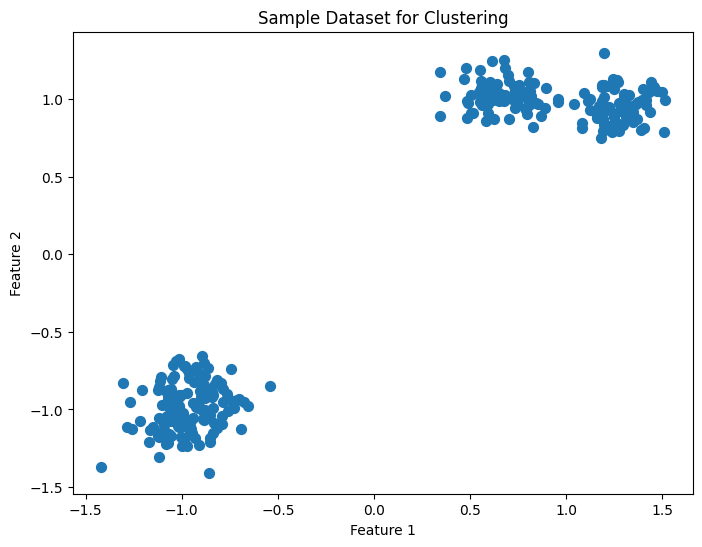

In [3]:
# Visualisasikan data mentah
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [4]:
# Label asal dan pusat kelompok yang dibuang buku, untuk dipakai sebagai pembanding (tambahan)
X_raw, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
print("ukuran per kelompok asal:", dict(sorted(Counter(y_blobs.tolist()).items())))
centers_raw = pd.DataFrame([X_raw[y_blobs == k].mean(axis=0) for k in range(4)], columns=["f1", "f2"])
print("pusat kelompok sebelum standardisasi:\n", centers_raw.round(2))
print("rentang data terstandardisasi:", X.min(axis=0).round(2), "s.d.", X.max(axis=0).round(2))

ukuran per kelompok asal: {0: 75, 1: 75, 2: 75, 3: 75}
pusat kelompok sebelum standardisasi:
      f1    f2
0  1.75  4.03
1 -6.34 -9.20
2 -5.90 -7.86
3  4.64  3.59
rentang data terstandardisasi: [-1.42 -1.41] s.d. [1.51 1.3 ]


**Interpretasi output.** Plot memperlihatkan **dua** kelompok yang jelas terpisah, bukan empat. Sel tambahan menjelaskan alasannya: `make_blobs` dengan `random_state=2024` menempatkan pusat kelompok 1 (−6,34; −9,20) dan kelompok 2 (−5,90; −7,86) sangat berdekatan, begitu pula kelompok 0 (1,75; 4,03) dan kelompok 3 (4,64; 3,59). Dengan `cluster_std=0.60`, dua pasang kelompok itu masing-masing **saling menempel**, sehingga data secara geometris lebih mirip "2 kelompok besar yang masing-masing berisi 2 sub-kelompok". Setiap kelompok asal berisi 75 titik. Setelah standardisasi, kedua fitur berada di rentang sekitar −1,4 sampai 1,5. Detail ini penting untuk membaca hasil resep berikutnya: algoritme apa pun akan kesulitan memisahkan pasangan kelompok yang tumpang tindih.

### Poin Penting
* *Clustering* tidak memakai label; `make_blobs` membuat data uji dengan kelompok yang diketahui.
* Dengan `random_state=2024`, dua pasang dari empat kelompok saling menempel, sehingga plot terlihat seperti dua kelompok.
* Standardisasi menyamakan skala fitur sebelum algoritme berbasis jarak dijalankan.

## Resep 10.2 — *K-means Clustering*

**Tujuan.** Membagi data *blobs* menjadi empat *cluster* dengan K-means, menggambar pusatnya, lalu memilih jumlah *cluster* dengan *elbow method*.

### Teori

**Intuisi.** K-means mewakili setiap *cluster* dengan satu titik pusat (*centroid*). Algoritmenya bergantian antara dua langkah: (1) setiap titik masuk ke pusat terdekat; (2) setiap pusat dipindahkan ke rata-rata anggotanya. Langkah ini diulang sampai keanggotaan tidak berubah. Hasilnya bagus jika *cluster* berbentuk bulat (*convex*, isotropik) dan berukuran mirip; buruk untuk bentuk memanjang, melengkung, atau kepadatan yang sangat berbeda.

**Matematika.** K-means meminimalkan *inertia* (jumlah kuadrat jarak dalam *cluster*):
$$J(C_1,\dots,C_K)=\sum_{k=1}^{K}\sum_{\mathbf{x}_i\in C_k}\lVert\mathbf{x}_i-\boldsymbol\mu_k\rVert^2,\qquad \boldsymbol\mu_k=\frac{1}{|C_k|}\sum_{\mathbf{x}_i\in C_k}\mathbf{x}_i.$$
Langkah *assignment* dan *update* masing-masing tidak pernah menaikkan $J$, sehingga algoritme (Lloyd) pasti konvergen, tetapi ke **optimum lokal**. Inisialisasi *k-means++* memilih pusat awal berjauhan (peluang sebanding kuadrat jarak ke pusat terdekat yang sudah terpilih) untuk mengurangi risiko itu. Karena $J$ selalu turun jika $K$ dinaikkan (dengan $K=n$, $J=0$), $K$ dipilih dengan ***elbow method***: cari titik di kurva $J(K)$ ketika penurunannya tiba-tiba melandai.

**Cara scikit-learn mengimplementasikannya.** `KMeans(n_clusters=8, init='k-means++', n_init='auto', max_iter=300, tol=1e-4, algorithm='lloyd', random_state=None)`.

* `fit_predict` menjalankan algoritme dan mengembalikan label; `cluster_centers_` menyimpan pusat dan `inertia_` menyimpan $J$.
* Sejak scikit-learn 1.4, `n_init='auto'` berarti **satu** kali inisialisasi bila memakai *k-means++* (10 kali untuk `init='random'`).
* `predict` dapat menempatkan titik baru ke pusat terdekat, jadi K-means bisa dipakai untuk data baru.

**Asumsi, kelebihan, keterbatasan.**

* Cepat ($O(nKd)$ per iterasi) dan mudah ditafsirkan; skala baik ke data besar.
* Harus menentukan $K$; sensitif terhadap skala fitur, outlier, dan inisialisasi; hanya menghasilkan batas linear (diagram Voronoi).

### Kode

In [5]:
# Muat pustaka
from sklearn.cluster import KMeans
# Pakai ulang dataset dari bagian sebelumnya
# Dataset sudah dimuat dan diskalakan sebagai X

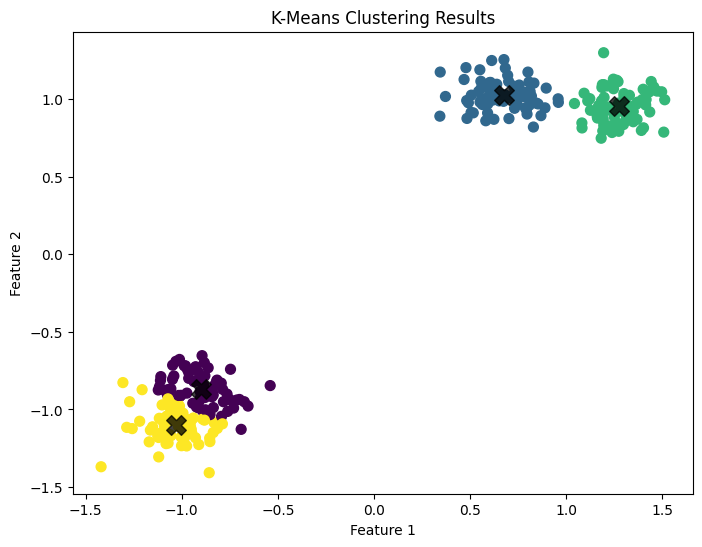

In [6]:
# Terapkan K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Gambar data yang sudah di-cluster
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.75, marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [7]:
# Kecocokan dengan kelompok asal, ukuran cluster, dan jumlah iterasi (tambahan)
from sklearn.metrics import adjusted_rand_score
print("ukuran cluster:", dict(sorted(Counter(y_kmeans.tolist()).items())))
print(f"inertia = {kmeans.inertia_:.3f}, iterasi = {kmeans.n_iter_}")
print("ARI terhadap kelompok asal make_blobs =", round(adjusted_rand_score(y_blobs, y_kmeans), 4))
print(pd.crosstab(pd.Series(y_blobs, name="kelompok asal"), pd.Series(y_kmeans, name="cluster K-means")))

ukuran cluster: {0: 71, 1: 77, 2: 73, 3: 79}
inertia = 7.295, iterasi = 4
ARI terhadap kelompok asal make_blobs = 0.8014
cluster K-means   0   1   2   3
kelompok asal                  
0                 0  75   0   0
1                10   0   0  65
2                61   0   0  14
3                 0   2  73   0


**Interpretasi output.**

* K-means menempatkan empat pusat (tanda X hitam): dua di kelompok kanan atas dan dua di kiri bawah. Ukuran *cluster* 71, 77, 73, dan 79; algoritme konvergen hanya dalam **4 iterasi** dengan *inertia* 7,295.
* Pasangan kanan atas (kelompok asal 0 dan 3) dipisahkan hampir sempurna: hanya 2 titik kelompok 3 yang masuk *cluster* kelompok 0. Pasangan kiri bawah (kelompok 1 dan 2) jauh lebih tercampur: 10 titik kelompok 1 dan 14 titik kelompok 2 masuk *cluster* yang "salah". Di plot, batas antara *cluster* ungu dan kuning memotong awan titik yang sebenarnya menyatu.
* ARI terhadap kelompok asal **0,801**. Kesalahannya bukan karena algoritme gagal, tetapi karena dua kelompok asal memang tumpang tindih; K-means memotongnya dengan garis lurus (batas Voronoi) di tengah.

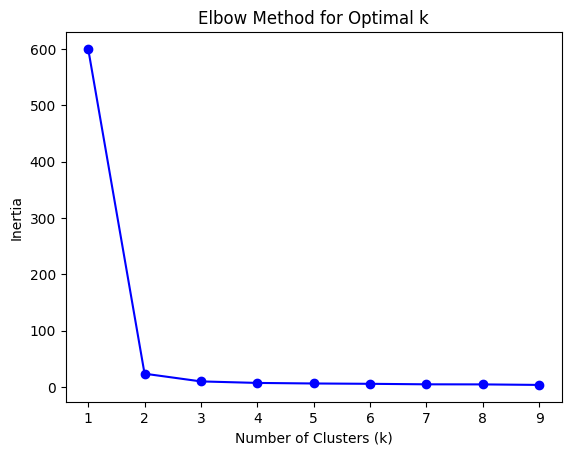

In [8]:
# Hitung dan gambar inertia clustering
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [9]:
# Nilai inertia dan penurunan relatifnya (tambahan)
elbow = pd.DataFrame({"k": list(k_values), "inertia": inertia})
elbow["turun dari k-1 (%)"] = (-elbow["inertia"].pct_change() * 100).round(1)
elbow.set_index("k").round(2).T

k,1,2,3,4,5,6,7,8,9
inertia,600.0,23.68,9.99,7.3,6.31,5.72,4.83,4.69,3.75
turun dari k-1 (%),NaN,96.10,57.80,27.0,13.60,9.20,15.70,2.90,19.90


**Interpretasi output.** *Inertia* turun dari 600 (k=1; sama dengan $n\times d$ = 300 × 2 karena data terstandardisasi) ke 23,68 pada k=2, yaitu penurunan **96,1 %**. Setelah itu penurunannya 57,8 % (k=3), 27,0 % (k=4), lalu makin kecil dan tidak teratur. "Siku" yang paling tajam ada di **k=2**, sesuai dua kelompok besar yang terlihat di plot. Siku kedua yang lebih lemah ada di k=3–4, sesuai sub-kelompok. Jadi kurva *elbow* di sini tidak menunjuk jelas ke k=4 yang dipakai buku; ini sering terjadi pada data nyata, sehingga *elbow* sebaiknya dikombinasikan dengan metrik lain (Resep 10.5) dan pengetahuan domain.

### Poin Penting
* K-means meminimalkan *inertia* dengan bergantian *assign*–*update*; di sini konvergen dalam 4 iterasi.
* Dua kelompok asal yang tumpang tindih menurunkan ARI menjadi 0,80 walaupun algoritme bekerja benar.
* Kurva *elbow* menunjuk paling jelas ke k=2 (inertia turun 96 %), bukan k=4; pilihan $K$ butuh lebih dari satu pertimbangan.

## Resep 10.3 — *Hierarchical Clustering*

**Tujuan.** Menerapkan *agglomerative clustering* empat *cluster* pada data yang sama dan menggambar *dendrogram* *linkage* Ward dengan SciPy.

### Teori

**Intuisi.** *Agglomerative clustering* membangun hierarki dari bawah: mula-mula setiap titik adalah *cluster* sendiri, lalu dua *cluster* terdekat digabung berulang kali sampai tinggal satu. Riwayat penggabungan digambar sebagai **dendrogram**; memotong pohon pada ketinggian tertentu menghasilkan sejumlah *cluster*. Pendekatan *divisive* (dari atas ke bawah) jarang dipakai dan tidak tersedia di scikit-learn.

**Matematika.** Jarak antar-*cluster* $A$ dan $B$ (*linkage*):
$$d_{\text{single}}=\min_{a\in A,b\in B}\lVert a-b\rVert,\quad d_{\text{complete}}=\max_{a,b}\lVert a-b\rVert,\quad d_{\text{average}}=\frac{1}{|A||B|}\sum_{a,b}\lVert a-b\rVert,$$
$$d_{\text{Ward}}(A,B)=\frac{|A||B|}{|A|+|B|}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2,$$
yaitu kenaikan total *within-cluster sum of squares* jika $A$ dan $B$ digabung. Ward karena itu "sejiwa" dengan K-means. Di dendrogram SciPy, tinggi sambungan Ward adalah $\sqrt{2\,d_{\text{Ward}}}$; lompatan tinggi yang besar menandakan penggabungan dua kelompok yang benar-benar terpisah.

**Cara scikit-learn mengimplementasikannya.** `AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward', distance_threshold=None)`.

* Isi **salah satu** dari `n_clusters` atau `distance_threshold` (pemotongan berdasarkan tinggi).
* `fit_predict` mengembalikan label; tidak ada `predict` untuk titik baru.
* scikit-learn tidak menggambar dendrogram; buku memakai `scipy.cluster.hierarchy.linkage` (matriks penggabungan $(n-1)\times4$) dan `dendrogram`.

**Asumsi, kelebihan, keterbatasan.**

* Tidak perlu menentukan $K$ di awal, dan dendrogram memperlihatkan struktur bertingkat.
* Waktu minimal $O(n^2)$ dan memori $O(n^2)$, sehingga tidak cocok untuk data sangat besar. Penggabungan bersifat rakus: tidak pernah dibatalkan.
* Hasil sangat bergantung pada *linkage* (single cenderung membentuk rantai, Ward cenderung bulat dan seimbang).

### Kode

In [10]:
# Muat pustaka
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Pakai ulang dataset dari bagian sebelumnya
# Dataset sudah dimuat dan diskalakan sebagai X

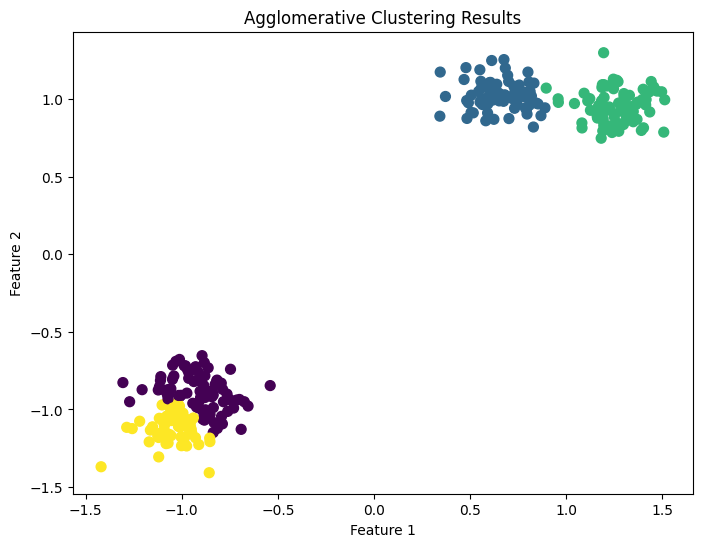

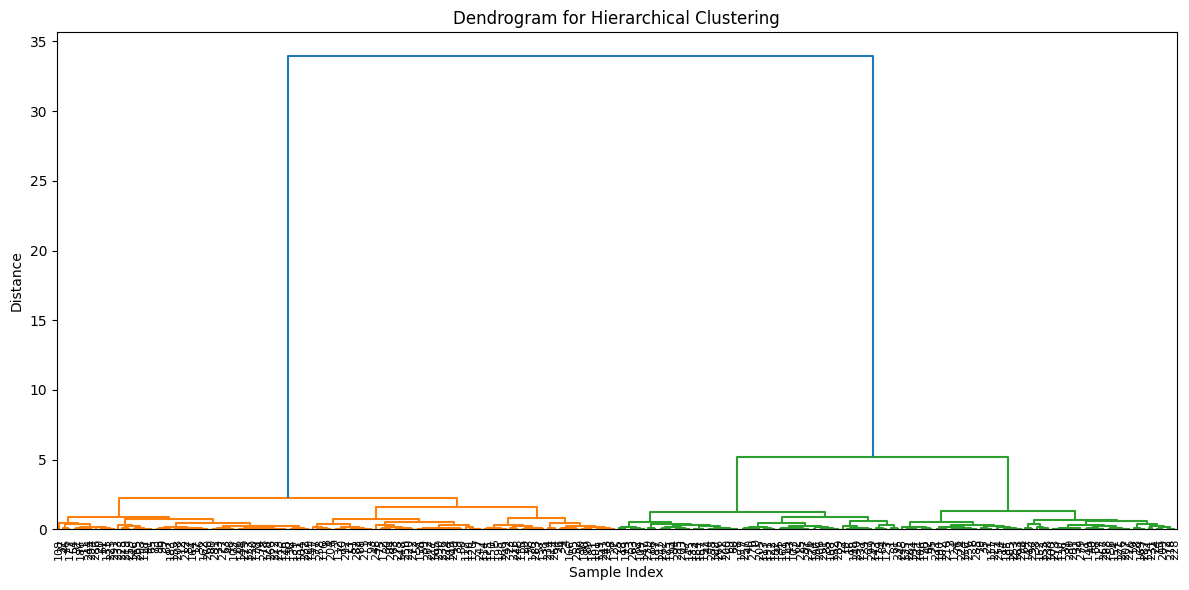

In [11]:
# Terapkan agglomerative clustering
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

# Gambar data yang sudah di-cluster
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Buat dendrogram dengan SciPy
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
# Kesamaan dengan K-means dan lompatan tinggi penggabungan terakhir (tambahan)
from scipy.cluster.hierarchy import fcluster
print("ARI agglomerative vs K-means     =", round(adjusted_rand_score(y_kmeans, y_agg), 4))
print("ARI agglomerative vs kelompok asal =", round(adjusted_rand_score(y_blobs, y_agg), 4))
print("tinggi 6 penggabungan terakhir:", linked[-6:, 2].round(2))
print("ARI potongan SciPy 4 cluster vs sklearn =", round(adjusted_rand_score(fcluster(linked, 4, criterion='maxclust'), y_agg), 4))

ARI agglomerative vs K-means     = 0.8823
ARI agglomerative vs kelompok asal = 0.7926
tinggi 6 penggabungan terakhir: [ 1.25  1.28  1.58  2.25  5.21 33.95]
ARI potongan SciPy 4 cluster vs sklearn = 1.0


**Interpretasi output.**

* *Agglomerative clustering* (Ward, 4 *cluster*) memberi pembagian yang mirip K-means: ARI antar-keduanya **0,882**, dan ARI terhadap kelompok asal **0,793** (sedikit di bawah K-means 0,801). Pada plot, perbedaannya hanya di perbatasan dua pasangan kelompok yang tumpang tindih.
* *Dendrogram* sangat informatif. Tinggi enam penggabungan terakhir adalah 1,25; 1,28; 1,58; 2,25; 5,21; dan **33,95**. Lompatan paling besar terjadi pada penggabungan terakhir (dari 5,21 ke 33,95): dua kelompok besar yang terpisah jauh. Lompatan berikutnya (2,25 → 5,21) memisahkan sub-kelompok. Memotong pohon di bawah 33,95 memberi 2 *cluster*, di bawah 5,21 memberi 3, dan di bawah 2,25 memberi 4. Ini konsisten dengan analisis *elbow*: struktur 2 kelompok jauh lebih kuat daripada 4.
* Potongan SciPy dengan 4 *cluster* identik dengan label scikit-learn (ARI 1,0), jadi kedua pustaka menjalankan algoritme yang sama.

### Poin Penting
* *Agglomerative clustering* menggabungkan *cluster* terdekat berulang kali; *linkage* Ward meminimalkan kenaikan *within-cluster SS*.
* Hasil 4 *cluster* mirip K-means (ARI 0,88 antar-keduanya).
* Lompatan tinggi di *dendrogram* (5,21 → 33,95) memperlihatkan bahwa struktur terkuat adalah 2 kelompok.

## Resep 10.4 — *Density-Based Clustering* dengan DBSCAN

**Tujuan.** Mengelompokkan data berbentuk dua bulan sabit (*moons*) dengan DBSCAN dan memilih parameter `eps` memakai *k-distance plot*.

### Teori

**Intuisi.** DBSCAN mendefinisikan *cluster* sebagai daerah **padat** yang dipisahkan daerah jarang. Sebuah titik adalah **titik inti** (*core*) jika di sekitarnya (radius `eps`) ada cukup banyak titik (`min_samples`). Titik inti yang saling terjangkau membentuk satu *cluster*; titik tepi (*border*) menempel pada *cluster* tanpa menjadi inti; sisanya adalah ***noise*** (label −1). Karena hanya bergantung pada kepadatan lokal, DBSCAN dapat menemukan bentuk melengkung seperti *moons* dan tidak memerlukan jumlah *cluster* di awal.

**Matematika.** Untuk titik $p$, lingkungan $N_\varepsilon(p)=\{q:\lVert p-q\rVert\le\varepsilon\}$ (termasuk $p$ sendiri). $p$ adalah inti jika $|N_\varepsilon(p)|\ge$ `min_samples`. $q$ *directly density-reachable* dari inti $p$ jika $q\in N_\varepsilon(p)$; *cluster* adalah himpunan maksimal titik yang saling terhubung lewat rantai keterjangkauan seperti itu. ***k-distance plot***: urutkan jarak setiap titik ke tetangga ke-$k$ ($k$ = `min_samples`); di daerah padat jarak ini kecil, di *noise* besar, sehingga "siku" kurva memberi kandidat $\varepsilon$.

**Cara scikit-learn mengimplementasikannya.** `DBSCAN(eps=0.5, min_samples=5, metric='euclidean')`.

* `fit_predict` mengembalikan label; −1 berarti *noise*. `core_sample_indices_` menyimpan indeks titik inti.
* Tidak ada `predict` untuk titik baru.
* `NearestNeighbors(n_neighbors=5).kneighbors(X)` pada data yang sama mengembalikan titik itu sendiri sebagai tetangga pertama (jarak 0); kolom ke-5 (`distances[:, 4]`) adalah jarak ke titik lain ke-4. Ini persis sesuai definisi titik inti DBSCAN, yang menghitung titik itu sendiri sebagai salah satu dari `min_samples`.

**Asumsi, kelebihan, keterbatasan.**

* Bentuk sembarang, tahan outlier, jumlah *cluster* otomatis.
* Satu `eps` untuk seluruh data: sulit jika kepadatan antar-*cluster* berbeda jauh (HDBSCAN/OPTICS lebih cocok). Sensitif terhadap skala fitur dan pilihan `eps`.

### Kode

In [13]:
# Muat pustaka
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# Buat dataset baru dengan noise
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)

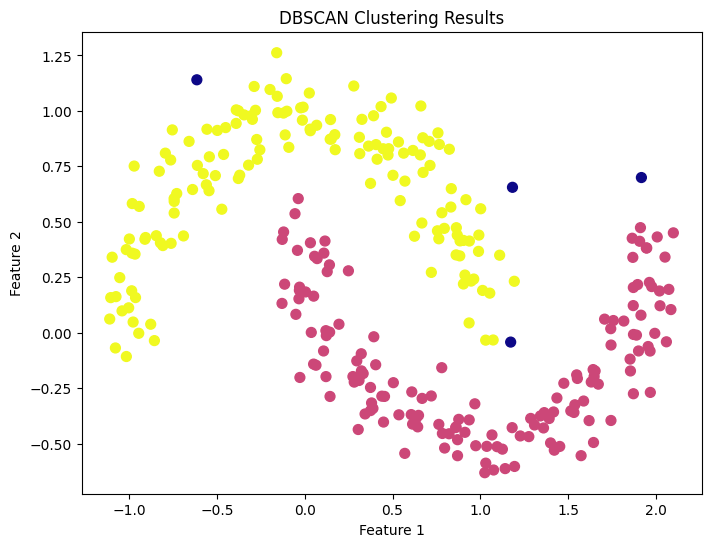

In [14]:
# Terapkan DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)

# Gambar hasil DBSCAN
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [15]:
# Jumlah cluster, noise, titik inti, dan kecocokan dengan bulan asal (tambahan)
_, y_moons = make_moons(n_samples=300, noise=0.1, random_state=2024)
print("label DBSCAN:", dict(sorted(Counter(y_db.tolist()).items())), "(-1 = noise)")
print(f"titik inti = {len(dbscan.core_sample_indices_)}, titik tepi = {300 - len(dbscan.core_sample_indices_) - (y_db == -1).sum()}")
print("ARI terhadap bulan asal =", round(adjusted_rand_score(y_moons, y_db), 4))
print("ARI K-means k=2 pada data yang sama =", round(adjusted_rand_score(y_moons, KMeans(n_clusters=2, random_state=2024).fit_predict(X)), 4))

label DBSCAN: {-1: 4, 0: 150, 1: 146} (-1 = noise)
titik inti = 290, titik tepi = 6
ARI terhadap bulan asal = 0.9604
ARI K-means k=2 pada data yang sama = 0.2408


**Interpretasi output.** Dengan `eps=0.2` dan `min_samples=5`, DBSCAN menemukan **dua *cluster*** (150 dan 146 titik) yang mengikuti bentuk kedua bulan sabit, ditambah **4 titik *noise*** (label −1, warna ungu tua di plot). Dari 300 titik, 290 adalah titik inti dan 6 titik tepi. ARI terhadap bulan asal **0,960**. Sebagai pembanding, K-means dengan k=2 pada data yang sama hanya mendapat ARI **0,241**, karena K-means memotong data dengan garis lurus dan membelah kedua bulan di tengah. Ini contoh paling jelas keunggulan metode berbasis kepadatan untuk *cluster* yang tidak berbentuk bulat.

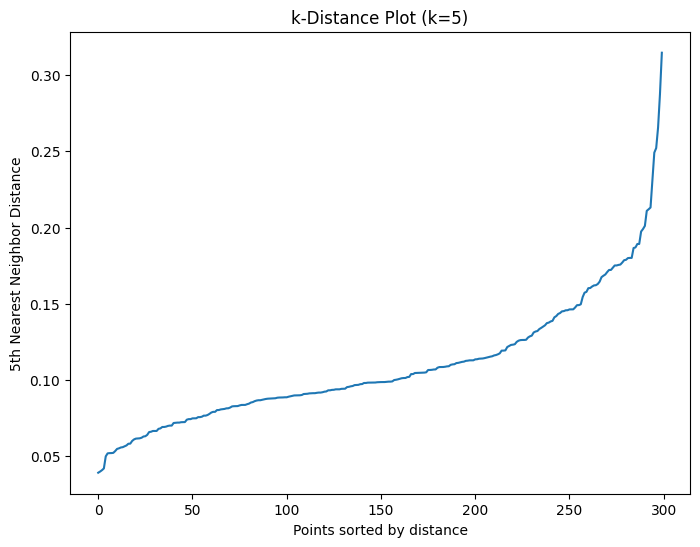

In [16]:
# Muat pustaka
from sklearn.neighbors import NearestNeighbors

# Bangkitkan nearest neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])

# Gambar k-distance
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

In [17]:
# Kuantil k-distance dan pengaruh eps terhadap hasil DBSCAN (tambahan)
print("kuantil jarak ke-5 (50/90/95/99 %):", np.quantile(distances, [.5, .9, .95, .99]).round(3))
print(f"titik dengan k-distance > 0,2 (bukan inti pada eps=0,2): {(distances > 0.2).sum()}")
rows = []
for eps in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows.append({"eps": eps, "cluster": len(set(lab) - {-1}), "noise": int((lab == -1).sum()),
                 "ARI": round(adjusted_rand_score(y_moons, lab), 3)})
pd.DataFrame(rows).set_index("eps").T

kuantil jarak ke-5 (50/90/95/99 %): [0.099 0.169 0.187 0.252]
titik dengan k-distance > 0,2 (bukan inti pada eps=0,2): 10


eps,0.10,0.15,0.20,0.25,0.30,0.40
cluster,18.000,4.000,2.00,1.0,1.0,1.0
noise,62.000,12.000,4.00,0.0,0.0,0.0
ARI,0.088,0.618,0.96,0.0,0.0,0.0


**Interpretasi output.** Kurva *k-distance* datar di sekitar 0,1 untuk sebagian besar titik (median 0,099), lalu naik tajam di ujung kanan: 95 % titik punya jarak ke tetangga ke-5 di bawah 0,187, dan 99 % di bawah 0,252. "Siku" kurva berada di sekitar **0,2**, jadi `eps=0.2` pilihan buku memang masuk akal. Hanya 10 titik punya *k-distance* > 0,2, yaitu kandidat *noise* atau titik tepi.

Tabel tambahan memperlihatkan seberapa sensitif DBSCAN terhadap `eps`: pada 0,10 data pecah menjadi 18 *cluster* dengan 62 *noise* (ARI 0,09); pada 0,15 masih 4 *cluster*; pada **0,20** tepat 2 *cluster* (ARI 0,96); dan mulai 0,25 kedua bulan **menyatu** menjadi satu *cluster* (ARI 0), karena ujung-ujung bulan yang berdekatan menjadi terjangkau. Rentang `eps` yang baik ternyata sempit (sekitar 0,18–0,22) untuk data ini.

### Poin Penting
* DBSCAN mendefinisikan *cluster* sebagai daerah padat; titik yang tidak padat dan tidak menempel ke *cluster* menjadi *noise* (−1).
* Pada *moons*, DBSCAN mendapat ARI 0,96, sedangkan K-means hanya 0,24.
* *K-distance plot* menunjuk `eps` ≈ 0,2; nilai sedikit lebih kecil memecah *cluster*, sedikit lebih besar menggabungkan kedua bulan.

## Resep 10.5 — Metrik Evaluasi *Cluster*

**Tujuan.** Mengukur kualitas K-means pada data *blobs* (tanpa standardisasi) dengan *silhouette score*, *Davies–Bouldin index*, dan *adjusted Rand index*.

### Teori

**Intuisi.** Tanpa label, kualitas *clustering* dinilai dari geometri hasilnya: *cluster* yang baik **rapat** di dalam dan **terpisah** dari *cluster* lain (metrik **internal**). Jika label sebenarnya kebetulan tersedia (misalnya untuk percobaan), kecocokan pembagian dengan label diukur dengan metrik **eksternal**.

**Matematika.**

* ***Silhouette*** titik $i$: $a(i)$ = rata-rata jarak ke titik lain di *cluster*-nya, $b(i)$ = rata-rata jarak terkecil ke *cluster* lain. $s(i)=\dfrac{b(i)-a(i)}{\max\{a(i),b(i)\}}\in[-1,1]$, dan skor = rata-rata $s(i)$. Mendekati 1 = rapat dan terpisah; mendekati 0 = di perbatasan; negatif = mungkin salah *cluster*.
* **Davies–Bouldin**: dengan $s_k$ rata-rata jarak anggota ke pusat *cluster* $k$ dan $d_{kl}$ jarak antar-pusat, $DB=\frac1K\sum_k\max_{l\ne k}\dfrac{s_k+s_l}{d_{kl}}$. Makin **kecil** makin baik (0 = ideal).
* ***Adjusted Rand Index***: berdasarkan semua pasangan titik, menghitung seberapa sering dua pembagian sepakat (keduanya "sama *cluster*" atau keduanya "beda *cluster*"), lalu dikoreksi terhadap kesepakatan kebetulan: $ARI=\dfrac{RI-E[RI]}{\max RI-E[RI]}$. ARI = 1 berarti identik (nomor *cluster* tidak berpengaruh), ≈0 berarti seperti acak.
* ***Calinski–Harabasz*** (disebut buku): rasio sebaran antar-*cluster* terhadap sebaran dalam-*cluster*, makin besar makin baik.

**Cara scikit-learn mengimplementasikannya.** `silhouette_score(X, labels, metric='euclidean', sample_size=None)`, `davies_bouldin_score(X, labels)`, `calinski_harabasz_score(X, labels)` memakai data + label; `adjusted_rand_score(labels_true, labels_pred)` hanya memakai dua himpunan label.

**Asumsi, kelebihan, keterbatasan.**

* Metrik internal berbasis jarak/pusat cenderung memihak *cluster* bulat (memihak K-means) dan bisa memberi nilai buruk untuk *cluster* berbentuk bulan sabit yang sebenarnya benar.
* *Silhouette* berbiaya $O(n^2)$; gunakan `sample_size` untuk data besar.
* Metrik eksternal hanya bisa dipakai bila label tersedia, yang jarang terjadi pada masalah *clustering* sungguhan.

### Kode

In [18]:
# Muat pustaka
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Bangkitkan dataset berlabel untuk evaluasi
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Fit KMeans untuk dipakai dengan metrik evaluasi
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

In [19]:
# Hitung silhouette score
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

# Hitung Davies-Bouldin index
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

# (Opsional) Hitung adjusted Rand index jika label sebenarnya diketahui
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

Silhouette Score: 0.534
Davies-Bouldin Index: 0.702
Adjusted Rand Index: 0.814


In [20]:
# Metrik untuk k = 2..7, termasuk Calinski-Harabasz, dan silhouette per cluster (tambahan)
from sklearn.metrics import calinski_harabasz_score, silhouette_samples
rows = []
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    rows.append({"k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
                 "calinski_harabasz": calinski_harabasz_score(X, lab), "ARI": adjusted_rand_score(y_true, lab)})
display(pd.DataFrame(rows).set_index("k").round(3))
s = silhouette_samples(X, y_kmeans)
print("silhouette rata-rata per cluster (k=4):", {k: round(float(s[y_kmeans == k].mean()), 3) for k in range(4)},
      "| titik dengan silhouette < 0:", int((s < 0).sum()))

,silhouette,davies_bouldin,calinski_harabasz,ARI
k,,,,
2,0.887,0.169,8523.616,0.497
3,0.768,0.390,8819.986,0.697
4,0.534,0.702,8670.779,0.814
5,0.446,0.879,7294.189,0.729
6,0.391,0.966,6461.760,0.633
7,0.400,0.942,6172.063,0.581


silhouette rata-rata per cluster (k=4): {0: 0.395, 1: 0.628, 2: 0.639, 3: 0.471} | titik dengan silhouette < 0: 2


**Interpretasi output.**

* Resep ini memakai *blobs* yang sama **tanpa** standardisasi. Untuk k=4: *silhouette* **0,534**, Davies–Bouldin **0,702**, dan ARI **0,814** (sedikit berbeda dari Resep 10.2 karena skala data berbeda).
* Tabel tambahan memperlihatkan bahwa metrik internal dan eksternal **tidak sepakat**. *Silhouette* (0,887) dan Davies–Bouldin (0,169) paling baik pada **k=2**, Calinski–Harabasz paling besar pada k=3 (8.820), sedangkan ARI terhadap label asal paling tinggi pada **k=4** (0,814). Metrik internal hanya melihat geometri, dan geometrinya memang paling "bersih" sebagai dua kelompok besar; hanya ARI yang tahu bahwa label asalnya empat.
* *Silhouette* per *cluster* untuk k=4 berkisar 0,40–0,64. Dua *cluster* dengan nilai terendah (0,395 dan 0,471) adalah pasangan kiri bawah, dua kelompok asal yang pusatnya paling berdekatan; dua *cluster* kanan atas mendapat 0,63–0,64. Ada 2 titik yang bahkan punya *silhouette* negatif (lebih dekat ke *cluster* tetangga daripada ke *cluster*-nya sendiri).
* Pelajaran: "*cluster* terbaik" bergantung pada metrik yang dipakai. Dalam praktik, label sebenarnya jarang ada, sehingga keputusan akhir biasanya memadukan beberapa metrik internal dengan tujuan bisnis.

### Poin Penting
* *Silhouette* (makin tinggi makin baik) dan Davies–Bouldin (makin rendah makin baik) adalah metrik internal; ARI adalah metrik eksternal yang butuh label.
* Untuk k=4: *silhouette* 0,534, DB 0,702, ARI 0,814.
* Metrik internal memilih k=2 sementara ARI memilih k=4; metrik internal mengukur kerapian geometri, bukan kebenaran label.

## Resep 10.6 — Memilih Algoritme *Clustering* yang Tepat

**Tujuan.** Membuat tiga dataset dengan struktur berbeda (*blobs*, *moons*, lingkaran bersarang) untuk memperlihatkan bahwa algoritme yang cocok bergantung pada bentuk data.

### Teori

**Intuisi.** Tidak ada algoritme *clustering* yang terbaik untuk semua data. Pertimbangan utama menurut buku:

| Faktor | K-means | Agglomerative | DBSCAN | Spectral / GMM |
|---|---|---|---|---|
| Bentuk *cluster* | Bulat (*convex*) | Bergantung *linkage* | Sembarang | Spectral: sembarang; GMM: elips |
| *Noise* | Semua titik dimasukkan | Semua titik dimasukkan | Ditandai −1 | GMM: peluang rendah |
| Skala data | Sangat baik | Buruk ($O(n^2)$) | Baik | Spectral: buruk; GMM: sedang |
| Parameter utama | $K$, inisialisasi | *linkage*, $K$/ambang | `eps`, `min_samples` | Spectral: graf, $K$; GMM: $K$, kovarians |

**Matematika.** Ketiga dataset dirancang menguji asumsi berbeda: *blobs* $N(\boldsymbol\mu_k,\sigma^2I)$ memenuhi asumsi K-means; *moons* adalah dua setengah lingkaran yang saling mengait, sehingga tidak dapat dipisahkan dengan batas Voronoi; *circles* (`factor=0.5`) adalah lingkaran kecil di dalam lingkaran besar, dengan pusat yang **sama**, sehingga metode berbasis pusat pasti gagal.

**Cara scikit-learn mengimplementasikannya.** `make_moons(noise=...)`, `make_circles(noise=..., factor=...)`, `make_blobs(...)`, masing-masing distandardisasi. Kode buku hanya **menggambar** ketiganya; sel tambahan menjalankan empat algoritme pada ketiga dataset dan mengukur ARI terhadap kelompok asal, agar tabel di atas bisa diuji.

**Asumsi, kelebihan, keterbatasan.** Dataset 2D sintetis membuat perbedaan algoritme sangat jelas; pada data berdimensi tinggi, struktur tidak bisa dilihat langsung, sehingga reduksi dimensi (PCA, t-SNE; Bab 3) dan metrik evaluasi (Resep 10.5) menjadi lebih penting.

### Kode

In [21]:
# Muat pustaka
from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.preprocessing import StandardScaler

# Buat dan skalakan beberapa dataset
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

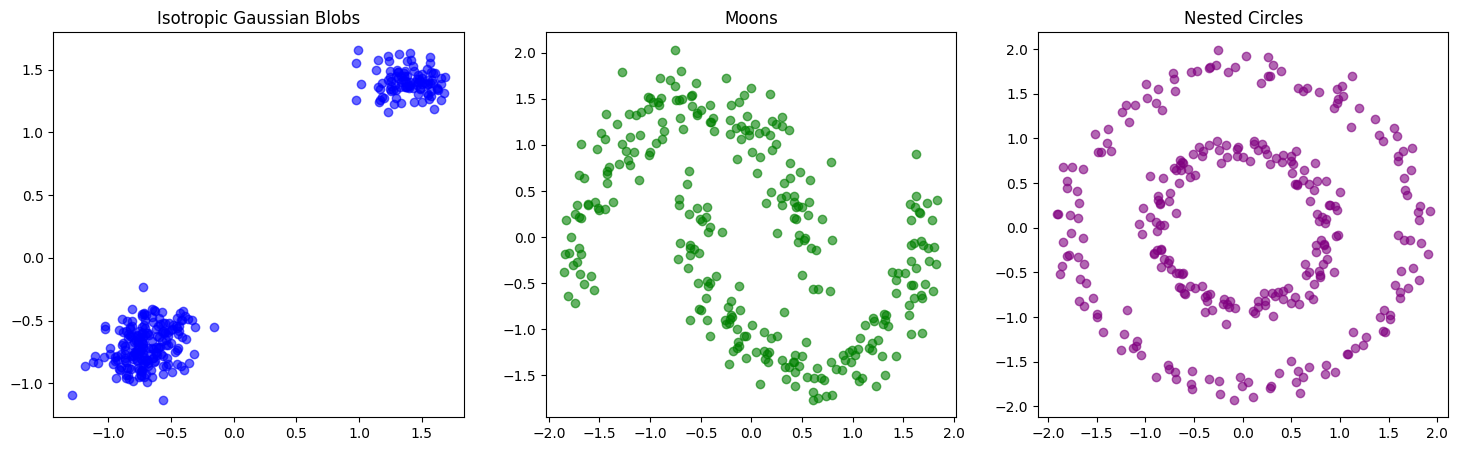

In [22]:
# Visualisasikan dataset
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1], c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

In [23]:
# Uji empat algoritme pada ketiga dataset, diukur dengan ARI terhadap kelompok asal (tambahan)
from sklearn.cluster import SpectralClustering
truth = {"blobs": make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)[1],
         "moons": make_moons(n_samples=300, noise=0.1, random_state=2024)[1],
         "circles": make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)[1]}
data = {"blobs": X_blobs, "moons": X_moons, "circles": X_circles}
algos = {
    "K-means": lambda k: KMeans(n_clusters=k, random_state=2024),
    "Agglomerative (ward)": lambda k: AgglomerativeClustering(n_clusters=k),
    "Agglomerative (single)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="single"),
    "DBSCAN (eps=0.3)": lambda k: DBSCAN(eps=0.3, min_samples=5),
    "Spectral (kNN)": lambda k: SpectralClustering(n_clusters=k, affinity="nearest_neighbors", random_state=2024),
}
table = pd.DataFrame({name: {algo: adjusted_rand_score(truth[name], make(len(set(truth[name]))).fit_predict(Xd))
                             for algo, make in algos.items()} for name, Xd in data.items()})
table.round(3)

/home/claude/venvs/sklcb/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/home/claude/venvs/sklcb/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,blobs,moons,circles
K-means,0.644,0.507,-0.003
Agglomerative (ward),0.552,0.470,-0.003
Agglomerative (single),0.569,0.000,1.000
DBSCAN (eps=0.3),0.570,0.948,1.000
Spectral (kNN),0.599,0.618,1.000


**Interpretasi output.** Ketiga plot memperlihatkan tantangan berbeda. Perlu dicatat, *blobs* di sini (`centers=3`, `random_state=2024`) lagi-lagi tampak sebagai **dua** kelompok, karena dua dari tiga pusat saling menempel di kiri bawah. Tabel tambahan menguji tabel teori dengan ARI terhadap kelompok asal:

* **Blobs:** semua algoritme mendapat ARI sedang, sekitar 0,55–0,64. Bukan karena algoritmenya buruk, tetapi dua kelompok yang menempel tidak bisa dipisahkan oleh metode mana pun tanpa informasi tambahan.
* **Moons:** DBSCAN unggul jauh (**0,948**), *spectral* sedang (0,618), K-means dan Ward sekitar 0,47–0,51 (memotong bulan dengan garis lurus). *Single linkage* gagal total (ARI 0): satu titik outlier membentuk *cluster* sendiri dan sisanya bergabung menjadi satu.
* **Circles:** K-means dan Ward **gagal total** (ARI ≈ 0), karena kedua lingkaran punya pusat yang sama. *Single linkage*, DBSCAN, dan *spectral* sempurna (**1,000**), karena ketiganya mengikuti keterhubungan titik, bukan jarak ke pusat.

Peringatan `Graph is not fully connected` dari *spectral clustering* berarti graf 10 tetangga terdekat terpecah menjadi beberapa komponen (misalnya karena outlier). Untuk *circles* hal ini justru membantu, tetapi secara umum peringatan ini tanda bahwa `n_neighbors` perlu diperiksa.

### Poin Penting
* Bentuk data menentukan algoritme: K-means/Ward untuk kelompok bulat, DBSCAN/*single*/*spectral* untuk bentuk melengkung atau bersarang.
* Pada *circles*, K-means mendapat ARI ≈ 0 sedangkan DBSCAN, *single linkage*, dan *spectral* mendapat 1,0.
* *Single linkage* sangat rentan terhadap outlier (ARI 0 pada *moons*).

## Resep 10.7 — Teknik *Clustering* Lanjutan

**Tujuan.** Membandingkan *spectral clustering* (graf *nearest neighbors*) dan *Gaussian mixture model* pada data *moons* yang distandardisasi.

### Teori

**Intuisi.**

* ***Spectral clustering*** memandang data sebagai **graf**: setiap titik dihubungkan ke tetangga terdekatnya. Dua bulan sabit adalah dua komponen yang hampir tidak terhubung, walaupun bentuknya melengkung. Algoritme mencari potongan graf yang memutus sesedikit mungkin sambungan, lalu menjalankan K-means di ruang baru (*spectral embedding*) tempat kedua komponen terpisah jelas.
* ***Gaussian mixture model* (GMM)** menganggap data dihasilkan oleh campuran $K$ distribusi normal. Setiap titik mendapat **peluang** keanggotaan (*soft clustering*), dan *cluster* boleh berbentuk elips dengan ukuran berbeda. Namun setiap komponen tetap berbentuk elips, jadi bentuk bulan sabit tetap sulit.

**Matematika.** *Spectral*: dari matriks afinitas $W$ (di sini $w_{ij}=1$ jika $j$ termasuk $k$ tetangga terdekat $i$, disimetrikan) dan derajat $D=\operatorname{diag}(\sum_j w_{ij})$, dibentuk Laplacian ternormalisasi $L=I-D^{-1/2}WD^{-1/2}$. Eigenvektor $L$ dengan eigenvalue terkecil memberi koordinat baru; K-means (`assign_labels='kmeans'`) dijalankan pada koordinat itu. GMM: $p(\mathbf{x})=\sum_{k}\pi_k\,N(\mathbf{x};\boldsymbol\mu_k,\Sigma_k)$; algoritme **EM** bergantian menghitung *responsibility* $\gamma_{ik}=\dfrac{\pi_kN(\mathbf{x}_i;\boldsymbol\mu_k,\Sigma_k)}{\sum_l\pi_lN(\mathbf{x}_i;\boldsymbol\mu_l,\Sigma_l)}$ (langkah E) dan memperbarui $\pi_k,\boldsymbol\mu_k,\Sigma_k$ sebagai rata-rata berbobot $\gamma_{ik}$ (langkah M), sampai *log-likelihood* konvergen.

**Cara scikit-learn mengimplementasikannya.**

* `SpectralClustering(n_clusters=8, affinity='rbf', n_neighbors=10, assign_labels='kmeans', random_state=None)`; dengan `affinity='nearest_neighbors'` dipakai graf 10 tetangga terdekat. Hanya `fit_predict`, tanpa `predict`.
* `GaussianMixture(n_components=1, covariance_type='full', max_iter=100, n_init=1, random_state=None)`; `predict_proba` memberi peluang keanggotaan, `bic`/`aic` membantu memilih $K$, dan ada `predict` untuk data baru.

**Asumsi, kelebihan, keterbatasan.**

* *Spectral* menangani bentuk non-*convex*, tetapi membutuhkan eigen-dekomposisi matriks $n\times n$ dan pilihan graf yang tepat.
* GMM fleksibel untuk *cluster* elips yang saling tumpang tindih dan memberi ketidakpastian, tetapi tetap mengasumsikan setiap *cluster* kira-kira normal.

### Kode

In [24]:
# Muat pustaka
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture
# Buat dataset dengan struktur kompleks
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X = StandardScaler().fit_transform(X)

/home/claude/venvs/sklcb/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


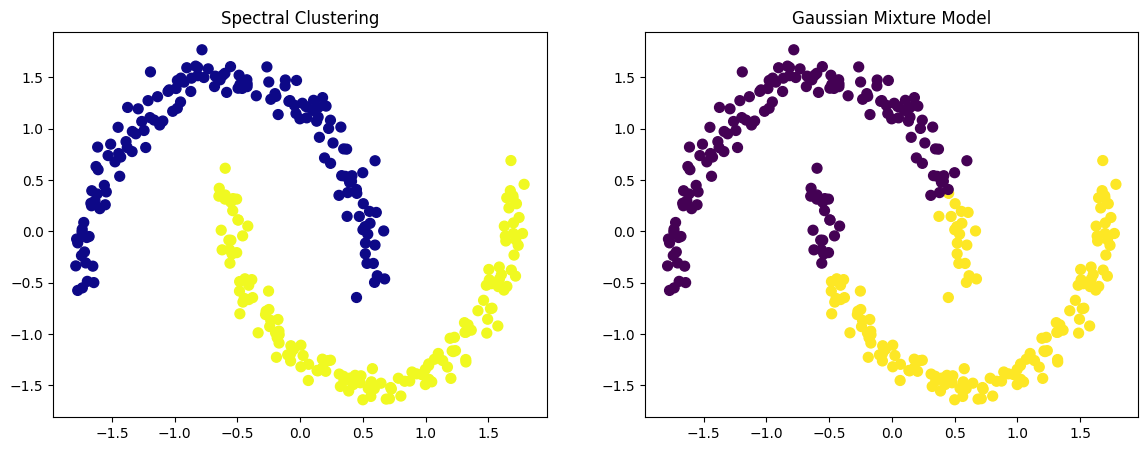

In [25]:
# Terapkan Spectral Clustering
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X)

# Terapkan Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

# Visualisasikan kedua hasil clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='plasma', s=50)
ax1.set_title("Spectral Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='viridis', s=50)
ax2.set_title("Gaussian Mixture Model")

plt.show()

In [26]:
# ARI terhadap bulan asal dan ketidakpastian GMM (tambahan)
_, y_moons05 = make_moons(n_samples=300, noise=0.05, random_state=2024)
print("ARI spectral =", round(adjusted_rand_score(y_moons05, y_spectral), 4))
print("ARI GMM      =", round(adjusted_rand_score(y_moons05, y_gmm), 4))
proba = gmm.predict_proba(X).max(axis=1)
print(f"peluang keanggotaan GMM terbesar per titik: median {np.median(proba):.3f}, titik dengan peluang < 0,9 = {(proba < 0.9).sum()}")
print("GMM salah bulan:", int(min((y_gmm != y_moons05).sum(), (y_gmm == y_moons05).sum())), "dari 300 titik")

ARI spectral = 1.0
ARI GMM      = 0.5265
peluang keanggotaan GMM terbesar per titik: median 1.000, titik dengan peluang < 0,9 = 40
GMM salah bulan: 41 dari 300 titik


**Interpretasi output.** Pada *moons* dengan *noise* lebih rendah (0,05), ***spectral clustering* memisahkan kedua bulan dengan sempurna** (ARI **1,0**), karena graf tetangga terdekat hampir tidak punya sambungan antar-bulan. GMM hanya mendapat ARI **0,527**: dengan dua komponen elips, GMM membagi data kira-kira menjadi bagian kiri atas dan kanan bawah, sehingga **41 dari 300 titik** masuk komponen yang salah (terlihat di plot kanan: ujung dalam bulan bawah ikut berwarna ungu, ujung dalam bulan atas ikut berwarna kuning). Peluang keanggotaan GMM umumnya sangat yakin (median 1,000), dan hanya 40 titik yang peluang terbesarnya di bawah 0,9. GMM salah **dengan yakin** karena modelnya (campuran elips) tidak cocok dengan bentuk data; peluang yang tinggi tidak menjamin pembagian yang benar.

### Poin Penting
* *Spectral clustering* memakai graf ketetanggaan dan berhasil sempurna pada *moons* (ARI 1,0).
* GMM memberi keanggotaan probabilistik dan *cluster* elips, tetapi gagal pada bentuk bulan sabit (ARI 0,53, 41 titik salah).
* Keyakinan model probabilistik hanya bermakna jika asumsi bentuk distribusinya cocok dengan data.

## Resep 10.8 — Latihan Praktis Model *Clustering*

**Tujuan.** Menerapkan materi bab pada tiga kasus: (1) K-means pada Iris dengan *silhouette* dan ARI, (2) DBSCAN vs K-means pada *moons* terstandardisasi, (3) PCA ke 2 dimensi lalu GMM pada Wine.

### Teori

* **Latihan 1 (Iris, 4 fitur, 3 spesies):** K-means $K=3$ **tanpa standardisasi**; dievaluasi dengan *silhouette* (internal) dan ARI terhadap spesies (eksternal). Setosa terpisah jelas dari dua spesies lain, sedangkan versicolor dan virginica saling tumpang tindih (bandingkan dengan Bab 8, tempat semua kesalahan klasifikasi Iris terjadi di antara keduanya).
* **Latihan 2 (*moons* terstandardisasi):** setelah standardisasi, jarak antar-titik membesar, sehingga `eps=0.3` (bukan 0,2 seperti Resep 10.4) dipakai.
* **Latihan 3 (Wine, 13 fitur, 3 kultivar):** data distandardisasi, diproyeksikan ke 2 komponen PCA (Bab 3: dua komponen menyimpan ±55 % variansi), lalu GMM 3 komponen. Kombinasi reduksi dimensi + model probabilistik ini umum dipakai untuk data berdimensi tinggi.

### Kode

### Kode — Latihan 1: *Clustering* dengan K-Means pada Dataset Iris

Silhouette Score: 0.553
Adjusted Rand Index: 0.730


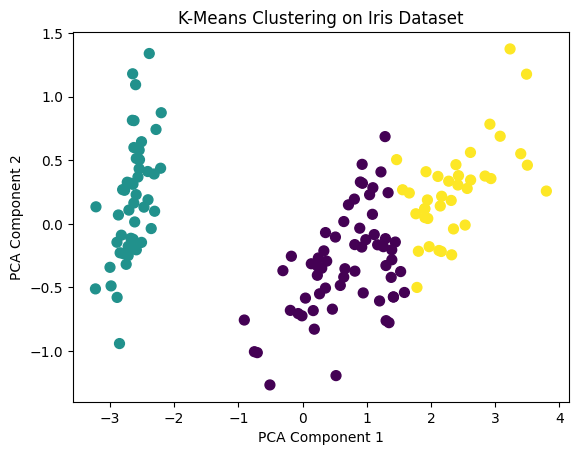

In [27]:
# Muat pustaka
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt

# Muat dataset
iris = load_iris()
X = iris.data
y_true = iris.target

# Buat dan latih model KMeans
kmeans = KMeans(n_clusters=3, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Evaluasi clustering
sil_score = silhouette_score(X, y_kmeans)
ari = adjusted_rand_score(y_true, y_kmeans)

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")

# Visualisasikan hasil cluster (proyeksi PCA)
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2).fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [28]:
# Tabel silang spesies vs cluster dan silhouette untuk K lain (tambahan)
print(pd.crosstab(pd.Series(iris.target_names[y_true], name="spesies"), pd.Series(y_kmeans, name="cluster")))
print("silhouette K=2..5:", {k: round(float(silhouette_score(X, KMeans(n_clusters=k, random_state=2024).fit_predict(X))), 3) for k in range(2, 6)})

cluster      0   1   2
spesies               
setosa       0  50   0
versicolor  48   0   2
virginica   14   0  36


silhouette K=2..5: {2: 0.681, 3: 0.553, 4: 0.495, 5: 0.36}


**Interpretasi output.** K-means pada Iris (tanpa standardisasi) mendapat *silhouette* **0,553** dan ARI **0,730**. Tabel silang menunjukkan **setosa** dikenali sempurna (50/50 di satu *cluster*), sedangkan **versicolor** dan **virginica** tercampur: 48 versicolor dan 14 virginica masuk *cluster* yang sama, dan 2 versicolor masuk *cluster* virginica. Jadi 16 bunga salah kelompok, persis di daerah tumpang tindih yang juga menjadi sumber kesalahan classifier *supervised* di Bab 8. Menariknya, *silhouette* terbaik justru pada **K=2** (0,681): secara geometri, Iris paling jelas terbagi menjadi "setosa" dan "bukan setosa".

### Kode — Latihan 2: Membandingkan DBSCAN dan K-Means pada Data *Moons*

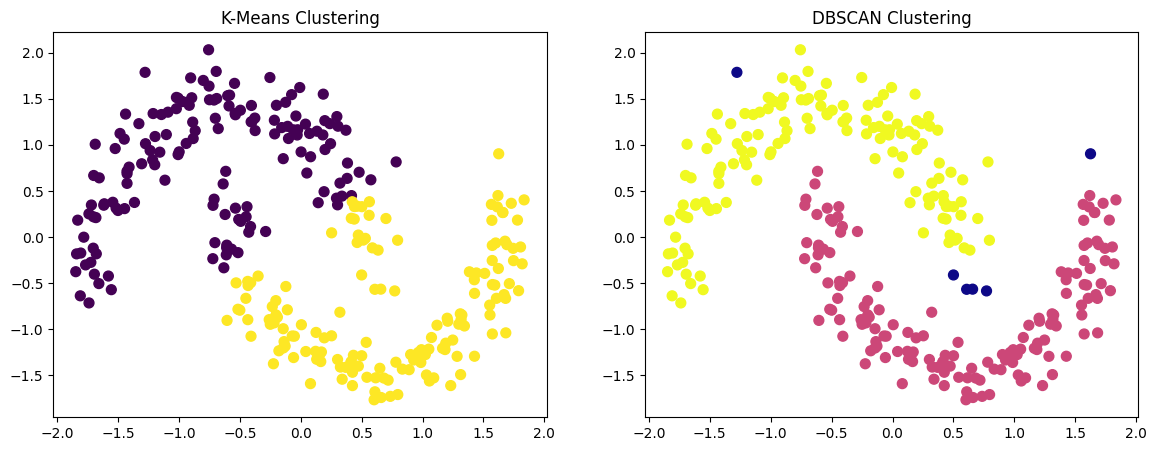

In [29]:
# Muat pustaka
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt

# Buat dan skalakan dataset
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X = StandardScaler().fit_transform(X)

# Terapkan KMeans dan DBSCAN
kmeans = KMeans(n_clusters=2, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

# Visualisasikan hasil clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', s=50)
ax1.set_title("K-Means Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma', s=50)
ax2.set_title("DBSCAN Clustering")

plt.show()

In [30]:
# Ukur kedua hasil terhadap bulan asal (tambahan)
print("K-means: ARI =", round(adjusted_rand_score(y_moons, y_kmeans), 4))
print("DBSCAN : ARI =", round(adjusted_rand_score(y_moons, y_dbscan), 4), "| label:", dict(sorted(Counter(y_dbscan.tolist()).items())))

K-means: ARI = 0.5072
DBSCAN : ARI = 0.9477 | label: {-1: 6, 0: 150, 1: 144}


**Interpretasi output.** Setelah standardisasi, DBSCAN dengan `eps=0.3` kembali menemukan kedua bulan (150 dan 144 titik, 6 *noise*) dengan ARI **0,948**, sedangkan K-means (k=2) hanya **0,507**. Plot kiri memperlihatkan K-means memotong data secara diagonal, sehingga ujung tiap bulan masuk ke *cluster* bulan lainnya. Nilai `eps` harus menyesuaikan skala: 0,2 cocok untuk data mentah (Resep 10.4), 0,3 untuk data terstandardisasi.

### Kode — Latihan 3: *Clustering* Data Berdimensi Tinggi dengan PCA + GMM

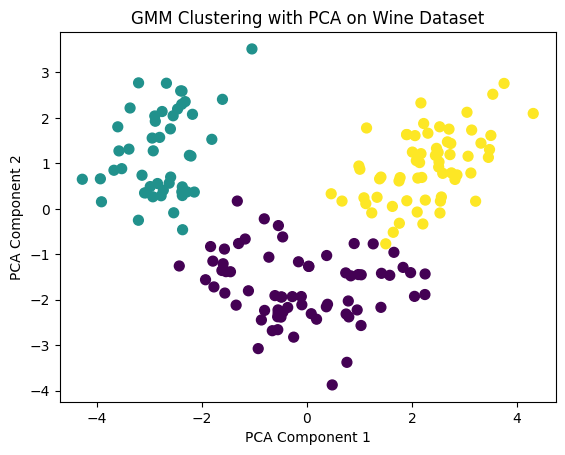

In [31]:
# Muat pustaka
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Muat dan pra-proses dataset
data = load_wine()
X = StandardScaler().fit_transform(data.data)

# Terapkan PCA untuk reduksi dimensi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=3, random_state=2024)
y_gmm = gmm.fit_predict(X_pca)

# Visualisasikan output yang sudah di-cluster
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_gmm, cmap='viridis', s=50)
plt.title("GMM Clustering with PCA on Wine Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [32]:
# Variansi yang disimpan PCA dan kecocokan dengan kultivar sebenarnya (tambahan)
print("variansi dijelaskan 2 komponen:", pca.explained_variance_ratio_.round(3), "total", round(pca.explained_variance_ratio_.sum(), 3))
print("ARI GMM(PCA-2D) vs kultivar =", round(adjusted_rand_score(data.target, y_gmm), 4))
print("ARI GMM pada 13 fitur penuh  =", round(adjusted_rand_score(data.target, GaussianMixture(n_components=3, random_state=2024).fit_predict(X)), 4))
print(pd.crosstab(pd.Series(data.target, name="kultivar"), pd.Series(y_gmm, name="komponen GMM")))

variansi dijelaskan 2 komponen: [0.362 0.192] total 0.554
ARI GMM(PCA-2D) vs kultivar = 0.9135
ARI GMM pada 13 fitur penuh  = 0.8975
komponen GMM   0   1   2
kultivar                
0              0   0  59
1             67   1   3
2              1  47   0


**Interpretasi output.** Dua komponen PCA menyimpan **55,4 %** variansi Wine (36,2 % + 19,2 %), sama seperti di Bab 3. GMM tiga komponen pada ruang 2D ini mencapai ARI **0,914** terhadap kultivar sebenarnya: kultivar 0 seluruhnya (59/59) di satu komponen, kultivar 2 hampir seluruhnya (47 dari 48), dan kultivar 1 67 dari 71, sehingga hanya **5 dari 178** anggur tidak cocok. GMM pada 13 fitur penuh justru sedikit lebih rendah (ARI 0,898). Reduksi dimensi membuang dimensi yang berisik dan membuat estimasi kovarians lebih stabil (13 fitur berarti 91 parameter kovarians per komponen, sedangkan 2D hanya 3).

### Poin Penting
* Iris: K-means mengenali setosa sempurna; versicolor/virginica tercampur (ARI 0,730), dan *silhouette* lebih menyukai K=2.
* *Moons* terstandardisasi: DBSCAN (`eps=0.3`) 0,948 vs K-means 0,507.
* Wine: PCA ke 2D lalu GMM mencapai ARI 0,914, lebih baik daripada GMM pada 13 fitur penuh (0,898).

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 10.1 Pengantar | Data sintetis berkelompok, standardisasi | `make_blobs`, `StandardScaler` | Dengan seed 2024, dua pasang kelompok saling menempel: tampak seperti 2 kelompok. |
| 10.2 K-means | *Inertia*, Lloyd, *k-means++*, *elbow* | `KMeans` | ARI 0,80; *elbow* paling tajam di k=2 (−96 %). |
| 10.3 *Hierarchical* | *Agglomerative*, *linkage* Ward, *dendrogram* | `AgglomerativeClustering`, `linkage`, `dendrogram` | Mirip K-means (ARI 0,88); lompatan 5,21 → 33,95 menandai 2 kelompok. |
| 10.4 DBSCAN | Titik inti/tepi/*noise*, *k-distance* | `DBSCAN`, `NearestNeighbors` | *Moons*: ARI 0,96 vs K-means 0,24; `eps` yang baik hanya ±0,18–0,22. |
| 10.5 Metrik Evaluasi | *Silhouette*, Davies–Bouldin, ARI, Calinski–Harabasz | `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score` | k=4: 0,534 / 0,702 / 0,814; metrik internal memilih k=2, ARI memilih k=4. |
| 10.6 Memilih Algoritme | Bentuk data vs asumsi algoritme | `make_moons`, `make_circles`, dll. | *Circles*: K-means ≈ 0, DBSCAN/*single*/*spectral* = 1,0. |
| 10.7 Teknik Lanjutan | Graf Laplacian, EM | `SpectralClustering`, `GaussianMixture` | *Moons*: *spectral* 1,0 vs GMM 0,53 (salah dengan yakin). |
| 10.8 Latihan Praktis | K-means Iris, DBSCAN vs K-means, PCA + GMM | `KMeans`, `DBSCAN`, `PCA`, `GaussianMixture` | Iris ARI 0,73; *moons* 0,95 vs 0,51; Wine PCA+GMM 0,91. |

**Langkah selanjutnya.** *Clustering* menemukan struktur tanpa label, tetapi setiap algoritme membawa definisi "kelompok" sendiri, dan evaluasinya selalu bersyarat. Ide kepadatan dan jarak dari bab ini dipakai ulang langsung di Bab 11 untuk mendeteksi titik yang **tidak** termasuk kelompok mana pun (outlier dan *novelty*), misalnya *Local Outlier Factor* yang bertumpu pada kepadatan lokal seperti DBSCAN.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 10.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Clustering: <https://scikit-learn.org/1.5/modules/clustering.html>
* scikit-learn User Guide — Gaussian mixture models: <https://scikit-learn.org/1.5/modules/mixture.html>
* Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory*, 28(2), 129–137.
* Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of SODA*, 1027–1035.
* Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of KDD*, 226–231.
* von Luxburg, U. (2007). A tutorial on spectral clustering. *Statistics and Computing*, 17(4), 395–416.
* Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
* Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193–218.